# Cd vs Re

forces from process.py and process_b3.py

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
f = pd.concat([pd.read_csv('processed/forces.csv'),
               pd.read_csv('processed/forces_b3.csv')])
log = pd.read_csv('data/run_log.csv')
df = f.merge(log, left_on='run', right_on='run_id')
len(df)

30

In [3]:
RHO = 998.
NU = 1.004e-6  # 20C, TODO use temp
L = 0.60

In [4]:
d = df.diameter_mm / 1000
df['Re'] = df.speed_m_s * d / NU
df['Cd'] = df.F_mean / (0.5 * RHO * df.speed_m_s**2 * d * L)
df.groupby('cylinder').Cd.mean().round(3)

cylinder
1.5in    1.153
1in      1.144
2in      1.178
Name: Cd, dtype: float64

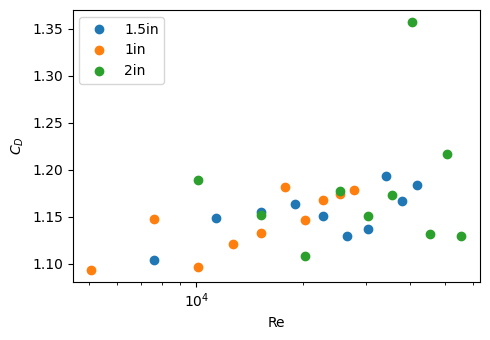

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for cyl, g in df.groupby('cylinder'):
    ax.plot(g.Re, g.Cd, 'o', label=cyl)
ax.set_xscale('log')
ax.set_xlabel('Re')
ax.set_ylabel('$C_D$')
ax.legend()
fig.tight_layout()
fig.savefig('figures/cd_vs_re.png', dpi=150)

In [6]:
df[['run', 'cylinder', 'speed_m_s', 'Re', 'Cd']].round(3)

,run,cylinder,speed_m_s,Re,Cd
0,1,1in,0.2,5059.761,1.094
1,2,1in,0.3,7589.641,1.148
2,3,1in,0.4,10119.522,1.097
3,4,1in,0.5,12649.402,1.121
4,5,1in,0.6,15179.283,1.133
5,6,1in,0.7,17709.163,1.182
6,7,1in,0.8,20239.044,1.147
7,8,1in,0.9,22768.924,1.167
8,9,1in,1.0,25298.805,1.174
9,10,1in,1.1,27828.685,1.179
